# 4. Short-duration XYZ with gaps

## Goal
Estimate the full XYZ spectrum from the **same seven-day realization** with
continuous and gapped observations. An approximate orbit-derived sine
reference places moving nulls; a multivariate spline learns its smooth matrix correction.

The short-segment idea is inspired by
[Burke et al., Noisy Pipelines I](https://arxiv.org/html/2610.28726v1).
This controlled matrix simulation is not their complete instrument pipeline.
The fitted residual is frequency-only over the week; the reference carries
time variation. We retain an exact joint-covariance point check after the
NUTS fit, without fitting secondary noise components.

## Setup
Run notebook 1 first. This lesson reuses its XYZ record and actual observation
windows. The small adapters below prepare library data and configure NUTS;
all multivariate spline inference is still performed by `log_psplines.fit`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from log_psplines import fit
from log_psplines.diagnostics import sampling_diagnostics

from lisa_case_studies.notebook_tools import (
    COLORS,
    matrix_errors,
    plot_nuts_traces,
    reference_config,
    reference_start,
    style,
)
from lisa_case_studies.orbit_reference import DAY
from lisa_case_studies.reference_matrix import (
    adaptive_partition,
    coefficient_data,
    matrix_mean,
    pool_log_frequency,
)
from lisa_case_studies.sine_reference import sine_reference_for
from lisa_case_studies.tutorial_data import (
    load_data,
    load_orbit_simulation,
    residual_matrix,
    workspace,
)

style()
data, simulation = load_orbit_simulation()
saved_windows = load_data("windows")
windows = {name: saved_windows[name] for name in ("continuous", "gapped")}
sine_reference = sine_reference_for(simulation)

## Step 1 — Keep the original time coordinates
The gap mask removes observations, not elapsed time. A common taper and
separate gap gate determine the two observation operators.

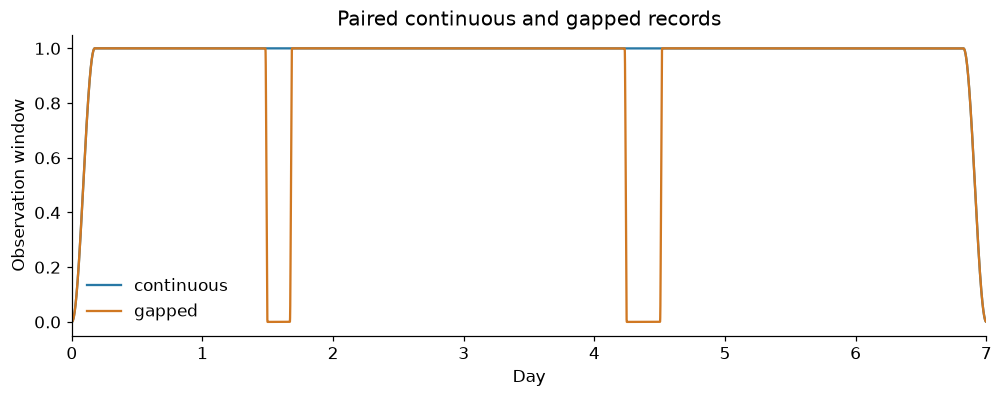

In [2]:
fig, ax = plt.subplots(layout="constrained")
for label, window in windows.items():
    ax.plot(data["time"] / DAY, window, color=COLORS[label], label=label)
ax.set(
    xlabel="Day",
    ylabel="Observation window",
    xlim=(0, 7),
    title="Paired continuous and gapped records",
)
ax.legend(frameon=False)
plt.show()

## Step 2 — Prepare the window-aware matrix reference
Freeze the first-generation envelope on day 0, while the three loop sine
factors track the known orbit epochs, as in notebook 3. For each window,
propagate the approximate sine factors into the **full same-frequency XYZ
covariance** $C_{w,0}(f)$. Whiten native coefficients by
its Cholesky factor before aggregating frequencies.

This preserves channel cross terms. It is still a Whittle approximation to
assume those whitened frequencies are independent. GapLike supplies the
masks/windows; its independent-channel likelihood is not substituted for XYZ.
[More on GapLike and XYZ](../gaplike_xyz.md).

In [3]:
reference = sine_reference.window_references(windows)
bins = np.flatnonzero(
    (simulation.frequency >= 0.4e-3) & (simulation.frequency <= 99e-3)
)
frequency = simulation.frequency[bins]
inputs = {}
for label, window in windows.items():
    coefficients = np.fft.rfft(data["xyz"] * window[:, None], axis=0)[bins] * np.sqrt(
        2 * simulation.dt / simulation.n
    )
    white = np.linalg.solve(
        np.linalg.cholesky(reference[label][bins]), coefficients[..., None]
    )[..., 0]
    enbw = simulation.n * np.sum(window**2) / np.sum(window) ** 2
    inputs[label] = coefficient_data(white, frequency, enbw=enbw)

## Step 3 — Freeze one adaptive partition
Use only observed gapped training data to select edges, then apply the same
partition to both observations. The pilot selects edges; actual complex
cross-products and their counts are summed without smoothing. Null
neighbourhoods retain native resolution. Bins never change during fitting.

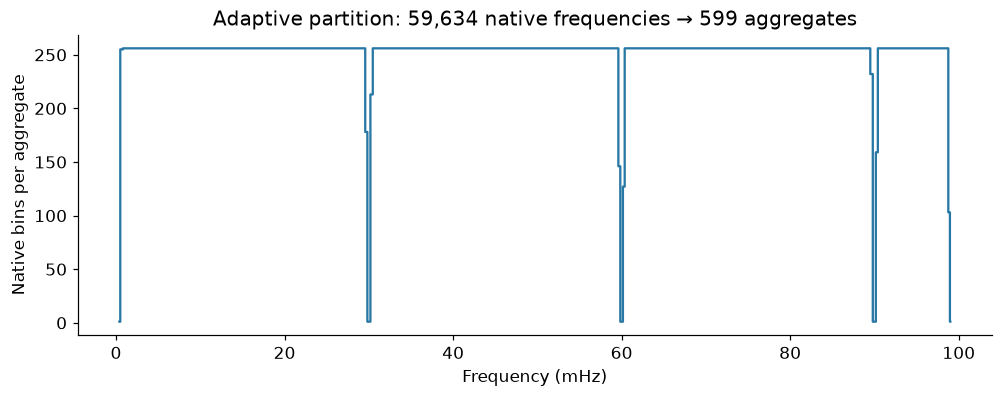

In [4]:
partition = adaptive_partition(inputs["gapped"])
pooled = {
    label: pool_log_frequency(values, partition) for label, values in inputs.items()
}
assert partition.freq_bin_counts.sum() == len(frequency)
fig, ax = plt.subplots(layout="constrained")
ax.step(
    partition.f_coarse * 1000, partition.freq_bin_counts, where="mid", color=COLORS["X"]
)
ax.set(
    xlabel="Frequency (mHz)",
    ylabel="Native bins per aggregate",
    title=f"Adaptive partition: {len(frequency):,} native frequencies → {partition.Nc:,} aggregates",
)
plt.show()

## Step 4 — Fit a full multivariate correction
The physical model is $S(t,f)=L_0(t,f)R(f)L_0(t,f)^\dagger$ with a full
positive-definite spline matrix $R$. The library analytically integrates the
six Gaussian theta fields and restores their conditional draws afterward.
This integration is exact **for the chosen Whittle model**, not for the
joint gapped likelihood.

Use the same prior and basis for both observations, and two NUTS chains
per observation.
All post-warmup draws enter reconstruction; no chain is selected using truth.
Only the approximate sine reference supplies the dip geometry.

Protected singleton cells have rank-one empirical matrices, so we initialize
the log-diagonal correction at zero (identity innovation variances) and
smoothing scales at 0.3; theta remains integrated rather than fixed. The small
`reference_start()` compatibility context replaces
only the pinned library’s empirical initializer; data, coordinates, likelihood,
penalties, priors and NUTS remain unchanged. No library files are edited.

In [5]:
config, components = reference_config(pooled["gapped"], seed=207)
selected = {}
for label in windows:
    with reference_start():
        selected[label] = fit(pooled[label], config)
    assert selected[label].metadata["method"] == "nuts"
    assert selected[label].metadata["theta_parameterization"] == "marginalized"
    assert selected[label].vi is None

|00:07| LogPSpline | INFO | Spline model: SpectralComponents(channels=3, knots=10, degree=3, penaltyOrder=2, N=599, basis_shapes=[(599, 12), (599, 12), (599, 12), (599, 12), (599, 12), (599, 12), (599, 12), (599, 12), (599, 12)])


W1106 16:50:03.259447 2535545 cpp_gen_intrinsics.cc:74] Empty bitcode string provided for eigen. Optimizations relying on this IR will be disabled.


|01:03| LogPSpline | INFO | Spline model: SpectralComponents(channels=3, knots=10, degree=3, penaltyOrder=2, N=599, basis_shapes=[(599, 12), (599, 12), (599, 12), (599, 12), (599, 12), (599, 12), (599, 12), (599, 12), (599, 12)])


## Step 5 — Check sampling before looking at truth
Inspect both chains for each observation. The diagnostic table covers all
sampled and restored fields. NUTS samples the adopted Whittle target; it does
not restore the inter-frequency covariance omitted from that likelihood.

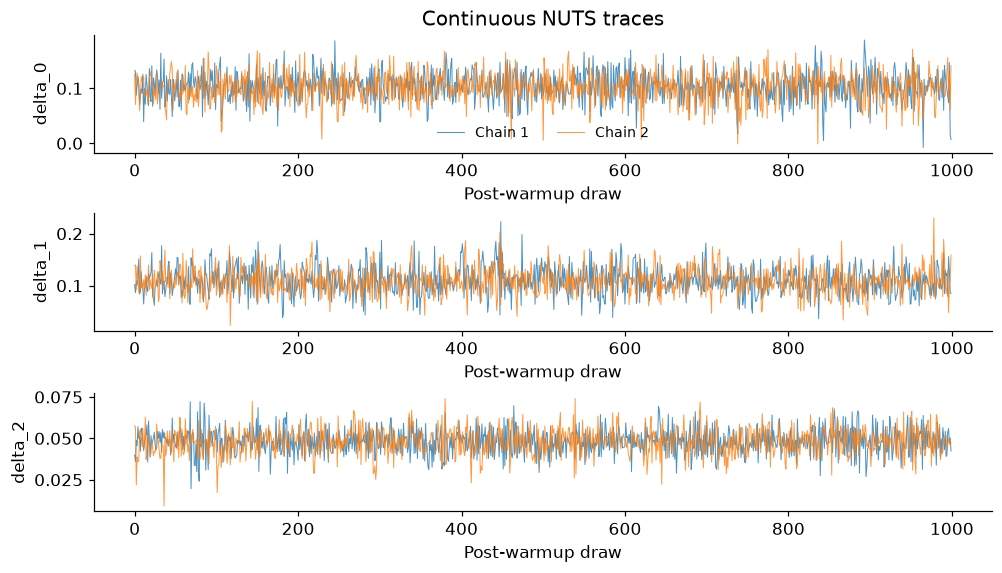

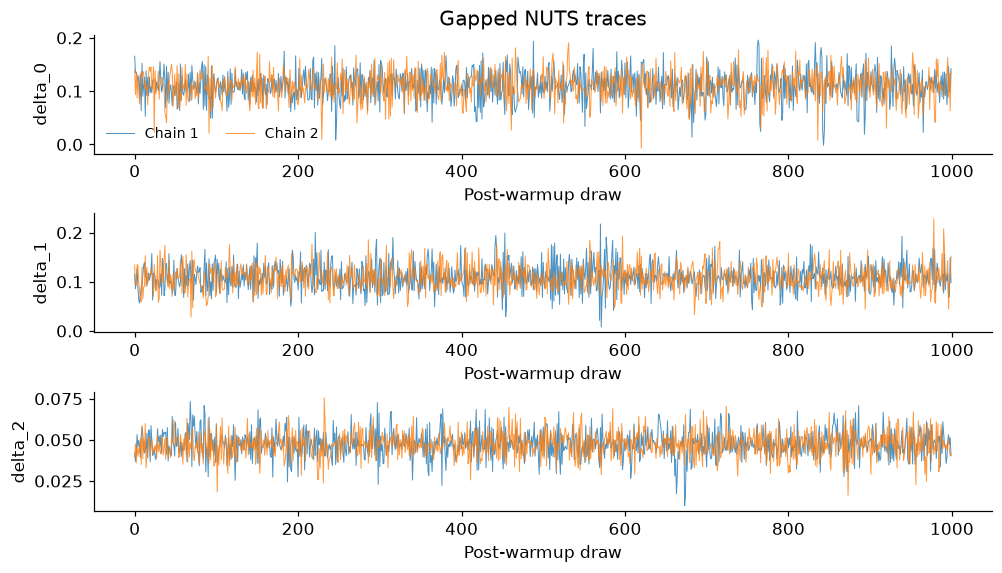

,Observation,factor,divergences,rhat_max,ess_bulk_min,ess_tail_min,max_treedepth_hits,step_size,n_draws
0,continuous,0,0,1.004,1745.571,1095.305,0,0.402,2000
1,continuous,1,0,1.002,1358.869,1040.318,0,0.387,2000
2,continuous,2,0,1.002,1319.635,973.435,0,0.244,2000
3,gapped,0,0,1.005,1494.685,1240.904,0,0.373,2000
4,gapped,1,0,1.003,1417.980,1180.683,0,0.350,2000
5,gapped,2,0,1.004,1344.699,1035.973,0,0.260,2000


In [6]:
checks = []
for label, result in selected.items():
    for row in sampling_diagnostics(result)["nuts"]:
        checks.append({"Observation": label, **row})
    plot_nuts_traces(result, label=label.capitalize())
    plt.show()
nuts_checks = pd.DataFrame(checks)
display(nuts_checks.round(3))
assert nuts_checks["divergences"].sum() == 0
assert nuts_checks["rhat_max"].max() < 1.05
assert nuts_checks["ess_bulk_min"].min() > 100
assert nuts_checks["ess_tail_min"].min() > 100
assert nuts_checks["max_treedepth_hits"].sum() == 0

## Step 6 — Recover the physical XYZ spectral matrix
Undo the reference transformation on a fixed native-frequency evaluation
support. Reconstruction uses restored theta draws, and averages complete
positive-definite matrices. Truth is used only from this point onward.

In [7]:
probe = np.unique(
    np.r_[
        np.rint(np.geomspace(0.4e-3, 99e-3, 400) * simulation.n * simulation.dt).astype(
            int
        ),
        *[
            np.flatnonzero(np.abs(simulation.frequency - f0) < 0.6e-3)
            for f0 in (0.03, 0.06, 0.09)
        ],
    ]
)
evaluation_frequency = simulation.frequency[probe]
evaluation_time = np.linspace(0, data["time"][-1], 17)
coordinate = np.clip(
    np.log(evaluation_frequency / frequency[0]) / np.log(frequency[-1] / frequency[0]),
    0,
    1,
)
factor = sine_reference.reference_factor(evaluation_time, evaluation_frequency)
truth = simulation.spectrum(evaluation_time, evaluation_frequency)
estimates = {"Sine reference": factor @ factor.conj().swapaxes(-1, -2)}
for label, result in selected.items():
    correction = matrix_mean(result.posterior, components, coordinate)
    estimates[label] = factor @ correction[None] @ factor.conj().swapaxes(-1, -2)

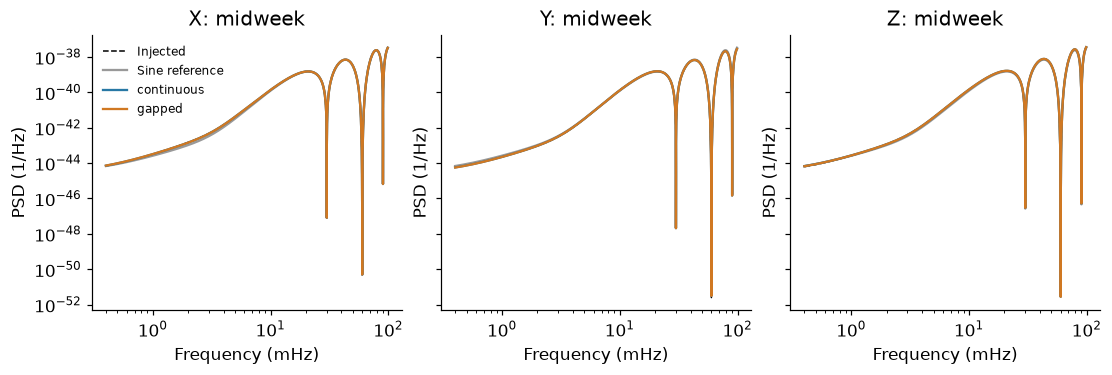

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), sharey=True, layout="constrained")
for j, (ax, channel) in enumerate(zip(axes, "XYZ", strict=True)):
    ax.loglog(
        evaluation_frequency * 1000,
        truth[8, :, j, j].real,
        "k--",
        lw=1,
        label="Injected",
    )
    for label, estimate in estimates.items():
        ax.loglog(
            evaluation_frequency * 1000,
            estimate[8, :, j, j].real,
            color=COLORS.get(label, "0.6"),
            label=label,
        )
    ax.set(xlabel="Frequency (mHz)", ylabel="PSD (1/Hz)", title=f"{channel}: midweek")
axes[0].legend(fontsize=8, frameon=False)
plt.show()

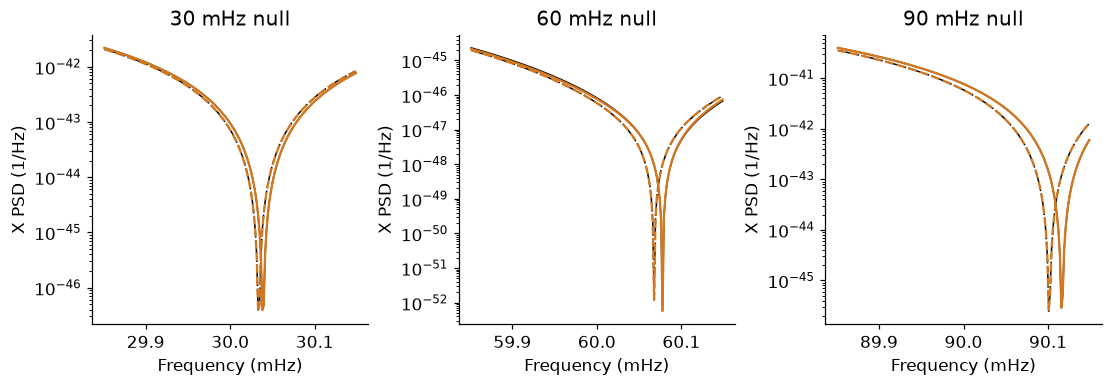

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), layout="constrained")
for ax, f0 in zip(axes, (0.03, 0.06, 0.09), strict=True):
    keep = np.abs(evaluation_frequency - f0) < 0.15e-3
    for t, ls in ((0, "--"), (-1, "-")):
        ax.semilogy(
            evaluation_frequency[keep] * 1000,
            truth[t, keep, 0, 0].real,
            color="k",
            ls=ls,
            lw=1,
        )
        ax.semilogy(
            evaluation_frequency[keep] * 1000,
            estimates["gapped"][t, keep, 0, 0].real,
            color=COLORS["gapped"],
            ls=ls,
        )
    ax.set(
        xlabel="Frequency (mHz)",
        ylabel="X PSD (1/Hz)",
        title=f"{f0 * 1000:.0f} mHz null",
    )
plt.show()

Black is injected; orange is the gapped reconstruction. Dashed curves show
day 0 and solid curves day 7. Geometry supplies the dip motion; smooth
splines do not have to discover the nulls unaided.

The error table uses the same fixed grid for every model: 17 times, a
logarithmic frequency overview and all native bins within 0.6 mHz of each
nominal null. Each time-frequency grid point receives equal weight, so this
is deliberately a null-focused score rather than a uniform-band average.

In [10]:
error_table = pd.DataFrame(
    {label: matrix_errors(estimate, truth) for label, estimate in estimates.items()}
).T
error_table.round(4)

,Auto log10 RMSE,Complex cross RMSE
Sine reference,0.0427,0.0690
continuous,0.0146,0.0160
gapped,0.0147,0.0167


## Step 7 — Keep an exact covariance benchmark
Take a small **fixed** set of adjacent native bins around each null. For
these retained XYZ features, the simulator can calculate the full joint
real Gaussian covariance, including frequency coupling and pseudo-covariance.
This is exact for this declared matrix simulator, not for the full time record.
It evaluates point reconstructions; it does not fit or marginalise theta
under the joint likelihood.

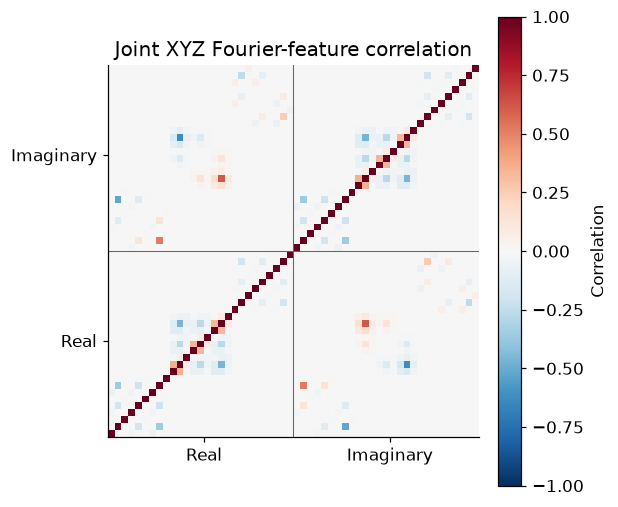

In [11]:
selected_bins = np.unique(
    (
        np.rint(np.array([0.03, 0.06, 0.09]) * simulation.n * simulation.dt).astype(
            int
        )[:, None]
        + np.array([-1, 0, 1])[None]
    ).ravel()
)
window = windows["gapped"]
nominal_covariance = sine_reference.feature_covariance(window, selected_bins)
std = np.sqrt(np.diag(nominal_covariance))
correlation = nominal_covariance / np.outer(std, std)
fig, ax = plt.subplots(figsize=(5.5, 4.5), layout="constrained")
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="RdBu_r", origin="lower")
half = len(correlation) // 2
ax.axvline(half - 0.5, color="0.4", lw=0.7)
ax.axhline(half - 0.5, color="0.4", lw=0.7)
ax.set(
    xticks=[half / 2, 1.5 * half],
    yticks=[half / 2, 1.5 * half],
    xticklabels=["Real", "Imaginary"],
    yticklabels=["Real", "Imaginary"],
    title="Joint XYZ Fourier-feature correlation",
)
fig.colorbar(image, ax=ax, label="Correlation")
plt.show()

Off-diagonal frequency blocks are the information discarded by the fast
Whittle fit. The matrix also retains within-frequency XYZ correlations.
Use four independent realizations for the following point check. The
injected-matrix row is an oracle control, never a model-selection input.
Outside the fitted frequency band, the recovered residual is extended
constantly at its nearest boundary; this assumption is explicit in the score.

In [12]:
full_coordinate = np.clip(
    np.log(simulation.frequency[1:] / frequency[0])
    / np.log(frequency[-1] / frequency[0]),
    0,
    1,
)
fitted_residual = matrix_mean(selected["gapped"].posterior, components, full_coordinate)
covariances = {
    "Reference only": nominal_covariance,
    "Gapped spline point": sine_reference.feature_covariance(
        window, selected_bins, correction=fitted_residual
    ),
    "Injected matrix (oracle)": simulation.feature_covariance(
        window, selected_bins, correction=residual_matrix(simulation.frequency[1:])
    ),
}
whitening = np.linalg.inv(np.linalg.cholesky(nominal_covariance))
validation = (
    np.asarray(
        [
            simulation.features(simulation.draw(seed), window, selected_bins)
            for seed in range(1007, 1011)
        ]
    )
    @ whitening.T
)
joint_scores = []
for label, covariance in covariances.items():
    covariance = whitening @ covariance @ whitening.T
    q = np.einsum("ri,ir->r", validation, np.linalg.solve(covariance, validation.T))
    joint_scores.append(
        {
            "Point model": label,
            "Mean exact joint q / dimension": q.mean() / covariance.shape[0],
            "Mean joint NLL / dimension (common constant omitted)": 0.5
            * (q.mean() + np.linalg.slogdet(covariance)[1])
            / covariance.shape[0],
        }
    )
pd.DataFrame(joint_scores).round(3)

/Users/avaj040/Documents/work/psd_estimation/lisa_logpsplines_case_studies/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/avaj040/Documents/work/psd_estimation/lisa_logpsplines_case_studies/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: overflow encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/avaj040/Documents/work/psd_estimation/lisa_logpsplines_case_studies/.venv/lib/python3.12/site-packages/numpy/linalg/_linalg.py:2366: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)


,Point model,Mean exact joint q / dimension,Mean joint NLL / dimension (common constant omitted)
0,Reference only,0.965,0.483
1,Gapped spline point,0.965,0.477
2,Injected matrix (oracle),0.966,0.478


## Checks and next steps
A joint quadratic near one is an independent point-model check, not proof
of posterior coverage. The main inference remains an approximate Whittle
fit. The reference, partition, priors and sampler settings were fixed before the
independent validation records were generated.

For the full derivation, see the [simulation notes](../notebook_models.md)
and [GapLike/XYZ explanation](../gaplike_xyz.md).

In [13]:
assert np.isfinite(truth).all()
for label in selected:
    estimate = estimates[label]
    assert np.isfinite(estimate).all()
    assert (
        len(
            [
                name
                for name in selected[label].posterior
                if name.startswith("weights_theta_")
            ]
        )
        == 6
    )
np.savez_compressed(
    workspace() / "short_xyz_nuts_recovery.npz",
    frequency=evaluation_frequency,
    time=evaluation_time,
    truth=truth,
    continuous=estimates["continuous"],
    gapped=estimates["gapped"],
    bin_starts=partition.J_start,
    bin_stops=partition.J_stop,
    bin_counts=partition.freq_bin_counts,
)
error_table.to_json(
    workspace() / "short_xyz_nuts_errors.json", orient="index", indent=2
)
nuts_checks.to_json(
    workspace() / "short_xyz_nuts_diagnostics.json", orient="records", indent=2
)